## 1. Imports

Import every library the notebook uses.

In [ ]:
import os
import re
import textwrap
import time
from functools import partial

import matplotlib.pyplot as plt
import pandas as pd
import tiktoken
from dotenv import load_dotenv
from google import genai
from huggingface_hub import login
from matplotlib.patches import Patch
from transformers import AutoTokenizer

from hebrew_token_tax.counters import (
    TokenCounter,
    make_gemini_counter,
    make_openai_counter,
    measure_overhead,
    probe_gemini,
    raw_gemini_count,
)
from hebrew_token_tax.data import build_paragraphs, load_aligned_pairs

## 2. Environment & clients

Load `.env`, check the keys, log in to Hugging Face, and create the API clients.

In [2]:
REQUIRED_KEYS = ("HF_TOKEN", "GEMINI_API_KEY")

load_dotenv()
missing = [key for key in REQUIRED_KEYS if not os.getenv(key)]
if missing:
    raise RuntimeError(f"Missing from .env: {', '.join(missing)}")

login(token=os.environ["HF_TOKEN"])
#anthropic_client = anthropic.Anthropic(api_key=os.environ["ANTHROPIC_API_KEY"])
gemini_client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


## 3. Token counters

Define the model constants and one token-counting function per provider.

In [ ]:
CLAUDE_MODEL_OLD = "claude-sonnet-4-5"
CLAUDE_MODEL_NEW = "claude-sonnet-5-5"
OPENAI_MODELS = ("gpt-4", "gpt-4o", "gpt-5")
GEMINI_MIN_MAJOR_VERSION = 3
GEMINI_VERSION_PATTERN = re.compile(r"gemini-(\d+)")
GEMINI_EXCLUDED_NAME_PARTS = (
    "image",
    "tts",
    "live",
    "transcribe",
    "embedding",
    "audio",
    "robotics",
    "nano-banana",
)
GEMINI_MODEL_PAUSE_SECONDS = 1.0
DICTALM_MODEL_ID = "dicta-il/dictalm2.0"
REFERENCE_PROVIDER = "Reference"
DICTALM3_PAIRS = (
    ("dicta-il/DictaLM-3.0-24B-Base", "mistralai/Mistral-Small-3.1-24B-Base-2503"),
    (
        "dicta-il/DictaLM-3.0-Nemotron-12B-Base",
        "nvidia/NVIDIA-Nemotron-Nano-12B-v2-Base",
    ),
    ("dicta-il/DictaLM-3.0-1.7B-Base", "Qwen/Qwen3-1.7B-Base"),
)
REFERENCE_NAMES = {
    "dicta-il/DictaLM-3.0-24B-Base": "DictaLM-3.0-24B",
    "mistralai/Mistral-Small-3.1-24B-Base-2503": "Mistral-Small-3.1",
    "dicta-il/DictaLM-3.0-Nemotron-12B-Base": "DictaLM-3.0-Nemotron-12B",
    "nvidia/NVIDIA-Nemotron-Nano-12B-v2-Base": "Nemotron-Nano-v2",
    "dicta-il/DictaLM-3.0-1.7B-Base": "DictaLM-3.0-1.7B",
    "Qwen/Qwen3-1.7B-Base": "Qwen3-1.7B",
}


def list_gemini_models() -> list[str]:
    """Return the model IDs this Gemini key can see, without the 'models/' prefix."""
    return sorted(
        model.name.removeprefix("models/") for model in gemini_client.models.list()
    )


def is_gemini_text_candidate(model_id: str) -> bool:
    """Keep stable and preview text models of generation 3 or newer, not aliases."""
    version = GEMINI_VERSION_PATTERN.match(model_id)
    return (
        version is not None
        and int(version.group(1)) >= GEMINI_MIN_MAJOR_VERSION
        and "-latest" not in model_id
        and not any(part in model_id for part in GEMINI_EXCLUDED_NAME_PARTS)
    )


def load_reference_tokenizer(model_id: str) -> AutoTokenizer | None:
    """Load only the tokenizer files of `model_id`, or None if it can't be fetched."""
    try:
        return AutoTokenizer.from_pretrained(model_id)
    except (OSError, ValueError) as error:
        print(f"unavailable: {model_id} ({type(error).__name__})")
        return None


def make_reference_counter(
    tokenizer: AutoTokenizer, model_id: str, note: str, tokenizer_id: str | None = None
) -> TokenCounter:
    """Return a local counter without special tokens, so its overhead is 0."""

    def count(text: str) -> int:
        return len(tokenizer.encode(text, add_special_tokens=False))

    overhead = measure_overhead(model_id, count)
    assert overhead == 0, f"{model_id}: overhead is not 0"
    return TokenCounter(
        provider=REFERENCE_PROVIDER,
        model=model_id,
        tokenizer_id=tokenizer_id,
        count=count,
        note=note,
    )


COUNTERS: list[TokenCounter] = [make_openai_counter(model) for model in OPENAI_MODELS]
for counter in COUNTERS:
    print(f"{counter.model}: tokenizer {counter.tokenizer_id}")

gemini_candidates = [
    model for model in list_gemini_models() if is_gemini_text_candidate(model)
]
print(f"\nGemini candidates ({len(gemini_candidates)}): {', '.join(gemini_candidates)}\n")

probes = []
for model in gemini_candidates:
    probes.append(probe_gemini(gemini_client, model))
    time.sleep(GEMINI_MODEL_PAUSE_SECONDS)
probe_table = pd.DataFrame(probes).set_index("model")
print()
print(probe_table.to_string())

for probe in probes:
    if probe["available"] == "yes":
        model = str(probe["model"])
        COUNTERS.append(
            make_gemini_counter(
                model,
                int(probe["overhead"]),
                partial(raw_gemini_count, gemini_client, model),
            )
        )

dictalm_tokenizer = AutoTokenizer.from_pretrained(DICTALM_MODEL_ID)
COUNTERS.append(
    make_reference_counter(
        dictalm_tokenizer, DICTALM_MODEL_ID, "Hebrew-optimized reference", "dictalm2"
    )
)
for dicta_model, base_model in DICTALM3_PAIRS:
    for model_id in (dicta_model, base_model):
        reference_tokenizer = load_reference_tokenizer(model_id)
        if reference_tokenizer is not None:
            COUNTERS.append(
                make_reference_counter(
                    reference_tokenizer, model_id, REFERENCE_NAMES[model_id]
                )
            )


## 4. Load & validate data

Load the dataset and check it is well-formed.

In [ ]:
N_PARAGRAPHS = 50  # how many article-paragraphs to sample
SEED = 42          # fixed seed -> same sample every run

pairs = load_aligned_pairs()
paragraphs = build_paragraphs(pairs, N_PARAGRAPHS, SEED)

print(f"{len(pairs)} sentence pairs -> {pairs['url_he'].nunique()} articles "
      f"-> sampled {len(paragraphs)} paragraphs")
print(f"Avg chars  HE: {paragraphs['he'].str.len().mean():.0f}  "
      f"EN: {paragraphs['en'].str.len().mean():.0f}")
print(f"Avg sentences per paragraph: {paragraphs['n_sentences'].mean():.1f}")
paragraphs[["pair_id", "topic", "n_sentences"]].head()

## 5. Sanity test

Run a quick sanity check of the token counters.

In [5]:
HE_SENTENCE = "הילד אכל תפוח בגינה"
EN_SENTENCE = "The boy ate an apple in the garden"
HE_WORD = "והבתים"


def token_pieces(model: str, text: str) -> list[str]:
    """Return the decoded text of each token `model` splits `text` into."""
    encoding = tiktoken.encoding_for_model(model)
    return [encoding.decode([token_id]) for token_id in encoding.encode(text)]


sanity = pd.DataFrame(
    [
        {
            "model": counter.model,
            "he": counter.count(HE_SENTENCE),
            "en": counter.count(EN_SENTENCE),
        }
        for counter in COUNTERS
    ]
).set_index("model")
sanity["ratio"] = (sanity["he"] / sanity["en"]).round(2)
print(sanity)

for model in OPENAI_MODELS:
    print(f"{model}: {token_pieces(model, HE_WORD)}")


def dictalm_pieces(text: str) -> list[str]:
    """Return the DictaLM token pieces of `text`, without special tokens."""
    return dictalm_tokenizer.convert_ids_to_tokens(
        dictalm_tokenizer.encode(text, add_special_tokens=False)
    )


side_by_side = pd.concat(
    [
        pd.Series([repr(piece) for piece in token_pieces("gpt-4o", HE_SENTENCE)]),
        pd.Series([repr(piece) for piece in dictalm_pieces(HE_SENTENCE)]),
    ],
    axis=1,
    keys=["o200k_base", "dictalm2"],
).fillna("")
print(side_by_side.to_string())


                                           he  en  ratio
model                                                   
gpt-4                                      20   8   2.50
gpt-4o                                      9   8   1.12
gpt-5                                       9   8   1.12
gemini-3-flash-preview                     11   8   1.38
gemini-3.1-flash-lite                      11   8   1.38
gemini-3.1-flash-lite-preview              11   8   1.38
gemini-3.1-pro-preview                     11   8   1.38
gemini-3.1-pro-preview-customtools         11   8   1.38
gemini-3.5-flash                           11   8   1.38
gemini-3.5-flash-lite                      11   8   1.38
gemini-3.6-flash                           11   8   1.38
gemini-3.7-flash                           11   8   1.38
gemini-3.8-flash                           11   8   1.38
gemini-4-argon                             11   8   1.38
dicta-il/dictalm2.0                        10   8   1.25
dicta-il/DictaLM-3.0-24B-Base  

## 6. Test loop

Run the token counters over the data.

In [6]:
RESULTS_DIR = os.path.join("..", "results")
RESULTS_CSV = os.path.join(RESULTS_DIR, "01_tokenizer_counts.csv")
CSV_COLUMNS = [
    "pair_id",
    "topic",
    "latin_share",
    "provider",
    "model",
    "tokenizer_label",
    "he_tokens",
    "en_tokens",
    "ratio",
    "he_chars",
    "en_chars",
]

if not os.path.isdir(RESULTS_DIR):
    raise FileNotFoundError(f"{RESULTS_DIR} not found; run from the notebooks/ folder")


def measure_paragraph(paragraph: pd.Series, counter: TokenCounter) -> dict[str, object]:
    """Count Hebrew and English tokens of one paragraph with one counter."""
    he_tokens = counter.count(paragraph["he"])
    en_tokens = counter.count(paragraph["en"])
    return {
        "pair_id": paragraph["pair_id"],
        "topic": paragraph["topic"],
        "latin_share": paragraph["latin_share"],
        "provider": counter.provider,
        "model": counter.model,
        "he_tokens": he_tokens,
        "en_tokens": en_tokens,
        "ratio": he_tokens / en_tokens,
        "he_chars": len(paragraph["he"]),
        "en_chars": len(paragraph["en"]),
    }


rows = []
for counter in COUNTERS:
    rows.extend(
        measure_paragraph(paragraph, counter) for _, paragraph in paragraphs.iterrows()
    )
    print(f"counted {counter.model}")
    if counter.provider == "Gemini":
        time.sleep(GEMINI_MODEL_PAUSE_SECONDS)
results = pd.DataFrame(rows)


def count_fingerprint(results: pd.DataFrame, model: str) -> tuple[int, ...]:
    """Return every Hebrew then English token count of `model`, ordered by paragraph."""
    model_rows = results[results["model"] == model].sort_values("pair_id")
    return tuple(model_rows["he_tokens"]) + tuple(model_rows["en_tokens"])


def tokenizer_key(counter: TokenCounter, results: pd.DataFrame) -> tuple[str, object]:
    """Identify a tokenizer by its public ID, or else by its full count fingerprint."""
    if counter.tokenizer_id is not None:
        return (counter.provider, counter.tokenizer_id)
    return (counter.provider, count_fingerprint(results, counter.model))


def group_by_tokenizer(
    counters: list[TokenCounter], results: pd.DataFrame
) -> list[list[TokenCounter]]:
    """Group counters of the same provider that share one tokenizer."""
    groups: dict[tuple[str, object], list[TokenCounter]] = {}
    for counter in counters:
        groups.setdefault(tokenizer_key(counter, results), []).append(counter)
    return list(groups.values())


model_to_label: dict[str, str] = {}
unnamed_per_provider: dict[str, int] = {}
for group in group_by_tokenizer(COUNTERS, results):
    first = group[0]
    models = ", ".join(counter.model for counter in group)
    if first.tokenizer_id is not None:
        name = first.tokenizer_id
        label = f"{name} ({first.note or models})"
        reason = "same tokenizer ID from tiktoken"
    elif first.provider == REFERENCE_PROVIDER:
        name = label = " = ".join(counter.note for counter in group)
        reason = f"identical counts on all {2 * len(paragraphs)} measurements"
    else:
        index = unnamed_per_provider.get(first.provider, 0)
        unnamed_per_provider[first.provider] = index + 1
        name = f"{first.provider.lower()}-{chr(ord('A') + index)}"
        label = f"{name} ({models})"
        reason = f"identical net counts on all {2 * len(paragraphs)} measurements"
    for counter in group:
        model_to_label[counter.model] = label
    if len(group) > 1:
        print(f"merged {models} -> {name}: {reason}")
    else:
        print(f"separate tokenizer {models} -> {name}")

for dicta_model, base_model in DICTALM3_PAIRS:
    if dicta_model in model_to_label and base_model in model_to_label:
        kept = model_to_label[dicta_model] == model_to_label[base_model]
        verdict = (
            "Dicta kept the base tokenizer"
            if kept
            else "Dicta changed the tokenizer (counts differ from the base)"
        )
        print(f"{dicta_model} vs {base_model}: {verdict}")

results["tokenizer_label"] = results["model"].map(model_to_label)
results = results[CSV_COLUMNS]
results.to_csv(RESULTS_CSV, index=False)
print(f"{len(results)} rows -> {RESULTS_CSV}")

counted gpt-4
counted gpt-4o
counted gpt-5


counted gemini-3-flash-preview


counted gemini-3.1-flash-lite


counted gemini-3.1-flash-lite-preview


counted gemini-3.1-pro-preview


counted gemini-3.1-pro-preview-customtools


... (4 outputs left out)

counted gemini-3.8-flash


counted gemini-4-argon


counted dicta-il/dictalm2.0
counted dicta-il/DictaLM-3.0-24B-Base
counted mistralai/Mistral-Small-3.1-24B-Base-2503
counted dicta-il/DictaLM-3.0-Nemotron-12B-Base
counted nvidia/NVIDIA-Nemotron-Nano-12B-v2-Base
counted dicta-il/DictaLM-3.0-1.7B-Base


counted Qwen/Qwen3-1.7B-Base
separate tokenizer gpt-4 -> cl100k_base
merged gpt-4o, gpt-5 -> o200k_base: same tokenizer ID from tiktoken
merged gemini-3-flash-preview, gemini-3.1-flash-lite, gemini-3.1-flash-lite-preview, gemini-3.1-pro-preview, gemini-3.1-pro-preview-customtools, gemini-3.5-flash, gemini-3.5-flash-lite, gemini-3.6-flash, gemini-3.7-flash, gemini-3.8-flash -> gemini-A: identical net counts on all 100 measurements
separate tokenizer gemini-4-argon -> gemini-B
separate tokenizer dicta-il/dictalm2.0 -> dictalm2
merged dicta-il/DictaLM-3.0-24B-Base, mistralai/Mistral-Small-3.1-24B-Base-2503, dicta-il/DictaLM-3.0-Nemotron-12B-Base, nvidia/NVIDIA-Nemotron-Nano-12B-v2-Base -> DictaLM-3.0-24B = Mistral-Small-3.1 = DictaLM-3.0-Nemotron-12B = Nemotron-Nano-v2: identical counts on all 100 measurements
merged dicta-il/DictaLM-3.0-1.7B-Base, Qwen/Qwen3-1.7B-Base -> DictaLM-3.0-1.7B = Qwen3-1.7B: identical counts on all 100 measurements
dicta-il/DictaLM-3.0-24B-Base vs mistralai/Mis

## 7. Analysis

Analyse the token counts.

In [7]:
LATIN_SHARE_THRESHOLD = 0.05
MAX_MODELS_IN_LABEL = 2


def compact_label(label: str) -> str:
    """Shorten 'name (m1, m2, ...)' to 'name (N models)' when the list is long."""
    if " = " in label:
        parts = label.split(" = ")
        if len(parts) <= MAX_MODELS_IN_LABEL:
            return label
        shown = " = ".join(parts[:MAX_MODELS_IN_LABEL])
        return f"{shown} (+{len(parts) - MAX_MODELS_IN_LABEL} more)"
    name, _, models = label.partition(" (")
    model_names = models.rstrip(")").split(", ")
    if len(model_names) <= MAX_MODELS_IN_LABEL:
        return label
    return f"{name} ({len(model_names)} models)"


per_tokenizer = results.drop_duplicates(["tokenizer_label", "pair_id"])
analysis = per_tokenizer.assign(
    he_chars_per_token=per_tokenizer["he_chars"] / per_tokenizer["he_tokens"],
    en_chars_per_token=per_tokenizer["en_chars"] / per_tokenizer["en_tokens"],
    latin_group=per_tokenizer["latin_share"]
    .lt(LATIN_SHARE_THRESHOLD)
    .map({True: "mostly pure", False: "mixed"}),
)

summary = analysis.groupby("tokenizer_label", sort=False).agg(
    provider=("provider", "first"),
    mean_ratio=("ratio", "mean"),
    median_ratio=("ratio", "median"),
    min_ratio=("ratio", "min"),
    max_ratio=("ratio", "max"),
    he_chars_per_token=("he_chars_per_token", "mean"),
    en_chars_per_token=("en_chars_per_token", "mean"),
)
print(summary.rename(index=compact_label).round(2).to_string())

by_group = analysis.groupby(["tokenizer_label", "latin_group"], sort=False).agg(
    mean_ratio=("ratio", "mean"),
    n_paragraphs=("pair_id", "size"),
)
print(by_group.rename(index=compact_label, level=0).round(2).to_string())

for tokenizer_label, group in analysis.groupby("tokenizer_label", sort=False):
    print(f"\n{compact_label(tokenizer_label)}")
    for label, extreme in (
        ("highest", group.nlargest(3, "ratio")),
        ("lowest", group.nsmallest(3, "ratio")),
    ):
        print(f"  {label}: {extreme.set_index('pair_id')['ratio'].round(2).to_dict()}")

                                                provider  mean_ratio  median_ratio  min_ratio  max_ratio  he_chars_per_token  en_chars_per_token
tokenizer_label                                                                                                                                 
cl100k_base (gpt-4)                               OpenAI        3.65          3.63       2.95       4.78                1.05                4.86
o200k_base (gpt-4o, gpt-5)                        OpenAI        1.50          1.49       1.23       1.91                2.58                4.93
gemini-A (10 models)                              Gemini        1.74          1.72       1.45       2.25                2.20                4.87
gemini-B (gemini-4-argon)                         Gemini        1.66          1.65       1.32       2.11                2.30                4.87
dictalm2 (Hebrew-optimized reference)          Reference        1.53          1.51       1.21       2.00                2.26      

## 8. Charts

Plot the results.

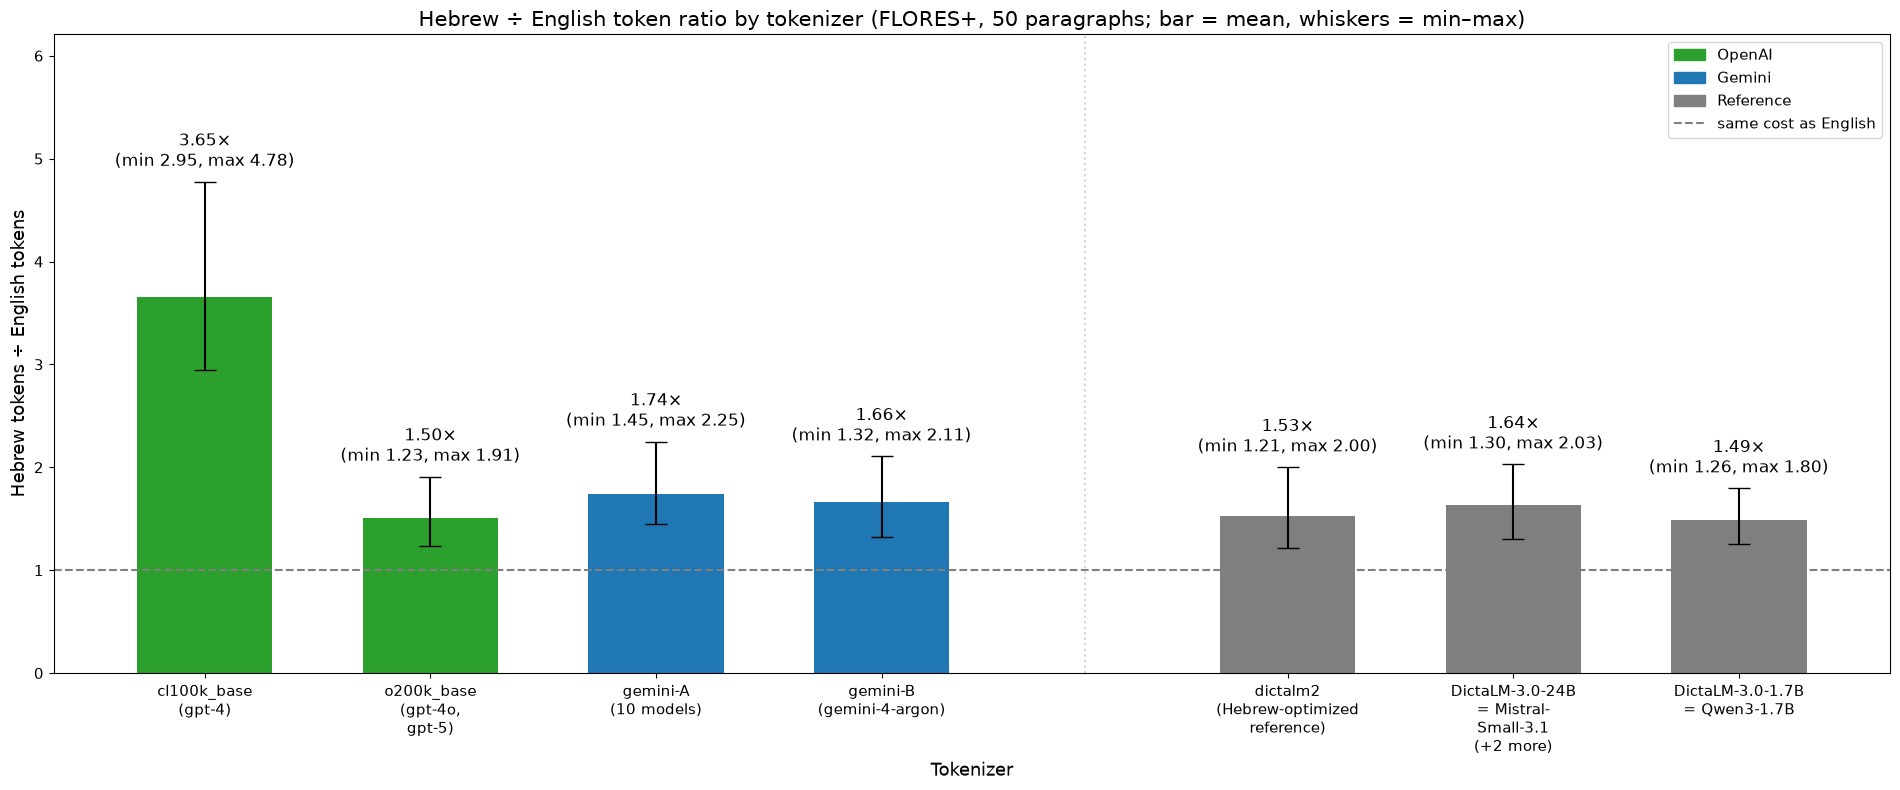

In [8]:
PROVIDER_COLORS = {
    "OpenAI": "tab:green",
    "Gemini": "tab:blue",
    REFERENCE_PROVIDER: "tab:gray",
}
REFERENCE_GAP = 0.8
TICK_WRAP_WIDTH = 18

n_paragraphs = analysis["pair_id"].nunique()
is_reference = (summary["provider"] == REFERENCE_PROVIDER).tolist()
positions = [
    index + (REFERENCE_GAP if reference else 0)
    for index, reference in enumerate(is_reference)
]
commercial_positions = [
    position
    for position, reference in zip(positions, is_reference)
    if not reference
]
reference_positions = [
    position for position, reference in zip(positions, is_reference) if reference
]
colors = [PROVIDER_COLORS.get(provider, "tab:gray") for provider in summary["provider"]]
tick_labels = [
    "\n".join(
        textwrap.fill(line, TICK_WRAP_WIDTH)
        for line in compact_label(label)
        .replace(" (", "\n(")
        .replace(", ", ",\n")
        .replace(" = ", "\n= ")
        .split("\n")
    )
    for label in summary.index
]
provider_handles = [
    Patch(color=PROVIDER_COLORS.get(provider, "tab:gray"), label=provider)
    for provider in summary["provider"].unique()
]

fig, ax = plt.subplots(figsize=(max(14, 2.3 * len(summary) + 3), 8))

ax.bar(
    positions,
    summary["mean_ratio"],
    yerr=[
        summary["mean_ratio"] - summary["min_ratio"],
        summary["max_ratio"] - summary["mean_ratio"],
    ],
    capsize=8,
    color=colors,
    width=0.6,
)
for position, mean, low, high in zip(
    positions, summary["mean_ratio"], summary["min_ratio"], summary["max_ratio"]
):
    ax.text(
        position,
        max(high, 1.0) + 0.1,
        f"{mean:.2f}×\n(min {low:.2f}, max {high:.2f})",
        ha="center",
        va="bottom",
        fontsize=12,
    )
parity_line = ax.axhline(
    1.0, linestyle="--", color="gray", label="same cost as English"
)
if commercial_positions and reference_positions:
    separator = (max(commercial_positions) + min(reference_positions)) / 2
    ax.axvline(separator, color="lightgray", linestyle=":", linewidth=1.5)

ax.set_xticks(positions, tick_labels, fontsize=11)
ax.tick_params(axis="y", labelsize=11)
ax.set_title(
    f"Hebrew ÷ English token ratio by tokenizer "
    f"(FLORES+, {n_paragraphs} paragraphs; bar = mean, whiskers = min–max)",
    fontsize=15,
)
ax.set_xlabel("Tokenizer", fontsize=13)
ax.set_ylabel("Hebrew tokens ÷ English tokens", fontsize=13)
ax.set_ylim(0, summary["max_ratio"].max() * 1.3)
ax.legend(handles=provider_handles + [parity_line], fontsize=11)

fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "01_tokenizer_ratios.png"), dpi=200)
plt.show()

## 9. Findings